# 3. Model 1: Logistic regression

**Rubric sections:** Model Development (20 pts) and Model Evaluation (20 pts).


**Why this model.** It's the simplest reasonable baseline: a linear boundary on seven
features. Its coefficients show directly which text properties push toward AI or Human.
Any more complex model has to beat it to justify the extra complexity.

**Assumptions.** The log-odds of AI is a linear function of the standardized features.
Rows are independent, which is why near-duplicates stay on one side of every split.
The model is scale-sensitive, so a `StandardScaler` is fit inside the pipeline on training folds only.

**Hyperparameters tuned** (16 combinations × 5 group-aware folds, chosen by ROC-AUC):

| Hyperparameter | Values | Meaning |
| --- | --- | --- |
| `C` | 1e-4 … 1e3 (8 values) | inverse regularization strength |
| `l1_ratio` | 0 (L2), 1 (L1) | L1 can set a weight to exactly zero |

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

# Works whether Jupyter starts in the repo root or in notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

FIGURES = ROOT / "reports" / "figures"
METRICS = ROOT / "reports" / "metrics"
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 140)


def show(name: str, width: int = 800) -> None:
    """Display a saved figure from reports/figures."""
    display(Image(filename=str(FIGURES / name), width=width))

## Train and evaluate

`RETRAIN = True` runs `src/train_logistic_regression.py` from scratch: it tunes on the training folds,
evaluates once on the test set, and saves metrics and figures.
Set it to `False` to only load the saved results.

In [2]:
RETRAIN = True

import train_logistic_regression

if RETRAIN or not (METRICS / "logistic_regression_metrics.json").exists():
    train_logistic_regression.main()

/Users/lucascoelho/Desktop/fall-2026/csce-478/project/human-vs-ai-ml-project/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Train rows: 40,000; test rows: 10,000; CV folds: 5


Best params: {'clf__C': 0.1, 'clf__l1_ratio': 1.0}; mean CV ROC-AUC 0.9998



Near-duplicate-group CV (selected config):
  train:      accuracy=0.9953±0.0002  precision=0.9955±0.0002  recall=0.9952±0.0003  f1=0.9953±0.0002  roc_auc=0.9999±0.0000
  validation: accuracy=0.9951±0.0009  precision=0.9951±0.0018  recall=0.9951±0.0016  f1=0.9951±0.0009  roc_auc=0.9998±0.0001

Full training partition: {'accuracy': 0.9953, 'precision': 0.9954, 'recall': 0.9952, 'f1': 0.9953, 'roc_auc': 0.9999}
Held-out test:           {'accuracy': 0.9944, 'precision': 0.9932, 'recall': 0.9956, 'f1': 0.9944, 'roc_auc': 0.9998}
Test confusion matrix:   {'true_human_pred_human': 4966, 'true_human_pred_ai': 34, 'true_ai_pred_human': 22, 'true_ai_pred_ai': 4978}

Template-family hold-out (training partition only):
  train:      accuracy=0.9959±0.0024  precision=0.9959±0.0024  recall=0.9959±0.0025  f1=0.9959±0.0024  roc_auc=0.9999±0.0001
  validation: accuracy=0.9888±0.0154  precision=0.9908±0.0151  recall=0.9836±0.0345  f1=0.9869±0.0198  roc_auc=0.9984±0.0029
    {'validation_families': [0, 

In [3]:
MODEL = "logistic_regression"
results = json.loads((METRICS / f"{MODEL}_metrics.json").read_text())
print("Selected hyperparameters:", results["best_params"])

Selected hyperparameters: {'clf__C': 0.1, 'clf__l1_ratio': 1.0}


## Tuning: training vs. validation score

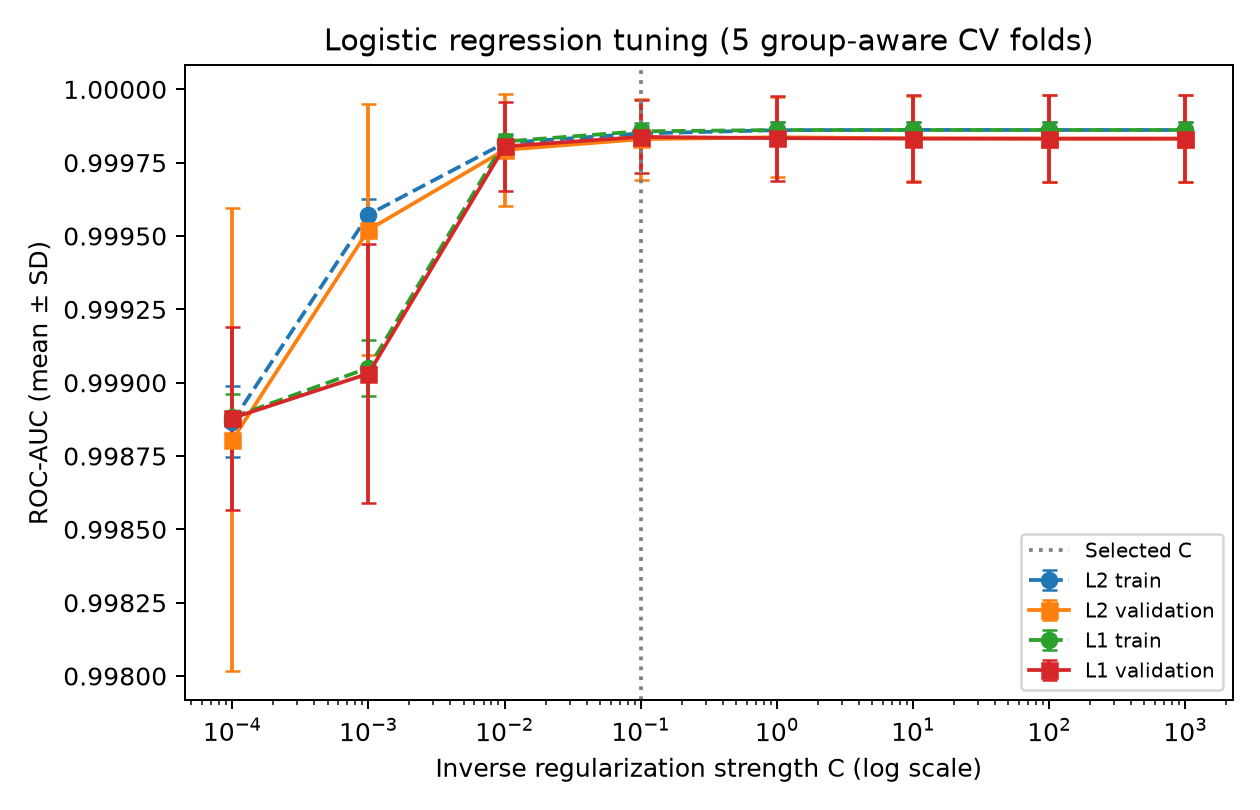

In [4]:
show("logistic_regression_tuning_curve.png", 900)

## Training vs. validation vs. test

In [5]:
def stage_row(block, part=None):
    return {m: (block[part][m]["mean"] if part else block[m]) for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]}

stages = pd.DataFrame({
    "CV train (mean)": stage_row(results["cv_near_duplicate_groups"], "train"),
    "CV validation (mean)": stage_row(results["cv_near_duplicate_groups"], "validation"),
    "Full training set": stage_row(results["full_train_metrics"]),
    "Held-out test": stage_row(results["test_metrics"]),
    "Unseen template families": stage_row(results["template_family_holdout"]["summary"], "validation"),
}).T.round(4)
stages

,accuracy,precision,recall,f1,roc_auc
CV train (mean),0.9954,0.9955,0.9952,0.9953,0.9999
CV validation (mean),0.9951,0.9951,0.9952,0.9951,0.9998
Full training set,0.9953,0.9954,0.9952,0.9953,0.9999
Held-out test,0.9944,0.9932,0.9956,0.9944,0.9998
Unseen template families,0.9888,0.9908,0.9836,0.9869,0.9984


## Test-set confusion matrix and ROC curve

In [6]:
pd.Series(results["test_confusion_matrix"]).to_frame("rows")

,rows
true_human_pred_human,4966
true_human_pred_ai,34
true_ai_pred_human,22
true_ai_pred_ai,4978


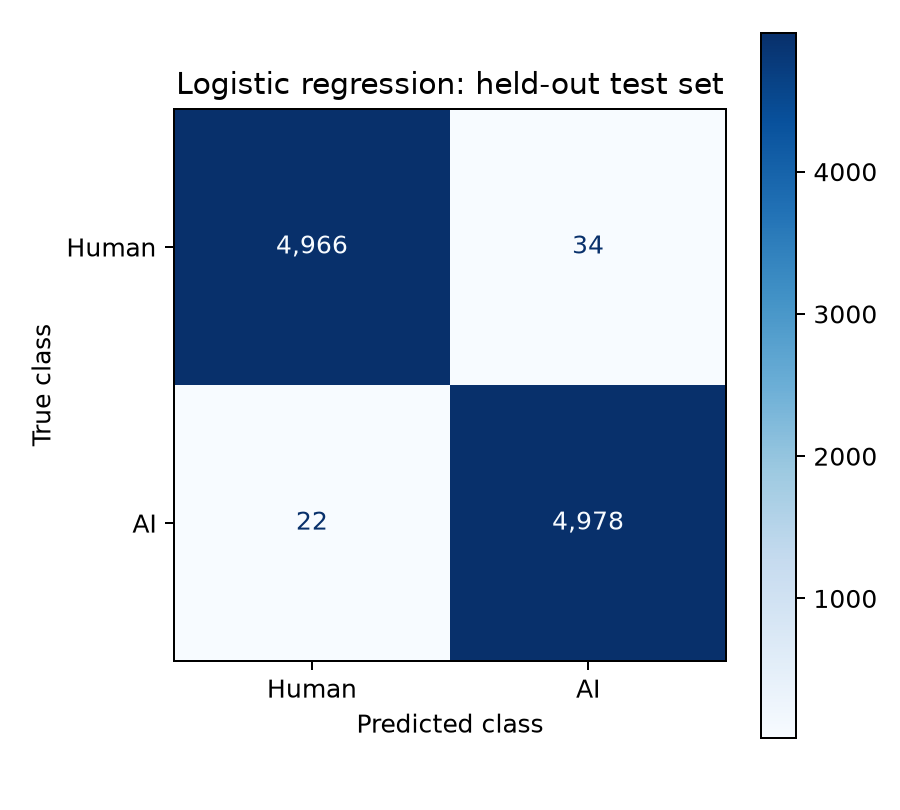

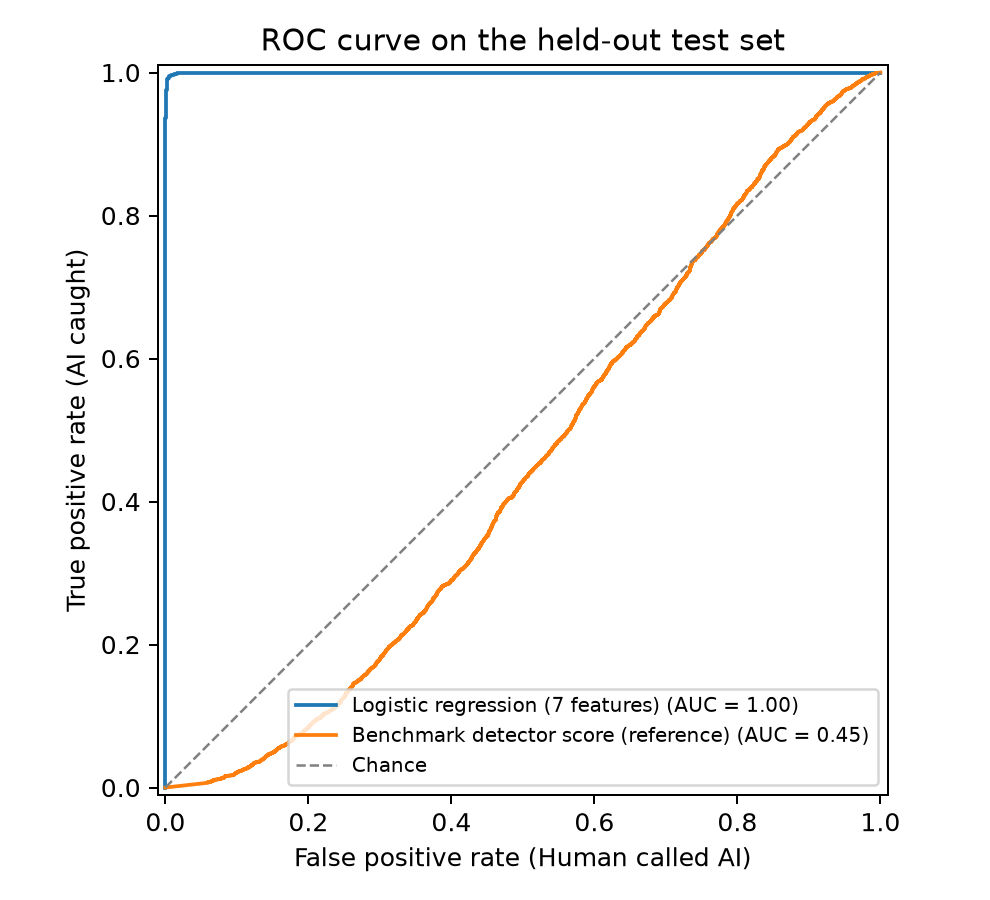

In [7]:
show("logistic_regression_confusion_matrix.png", 450)
show("logistic_regression_roc_curve.png", 500)

## Interpretation: standardized coefficients

In [8]:
pd.Series(results["standardized_coefficients"]).sort_values().round(3).to_frame("coefficient (log-odds per 1 SD)")

,coefficient (log-odds per 1 SD)
Text_Punctuation_Density,-3.988
Text_Word_Count,-0.879
Text_Burstiness,-0.143
Text_Guiraud_Root_TTR,0.000
Text_Average_Sentence_Length_Words,0.099
Text_Flesch_Kincaid_Grade_Level,3.602
Text_Average_Word_Length,6.618


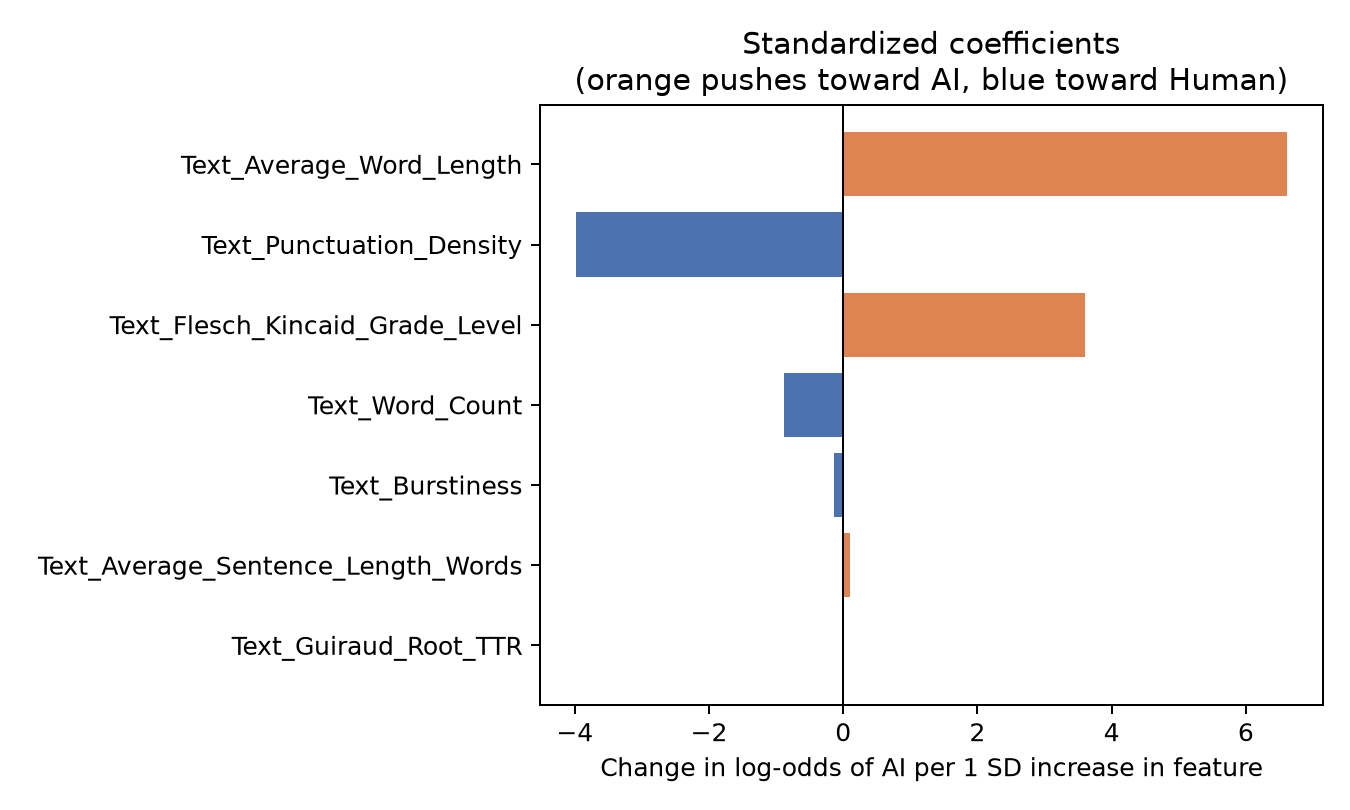

In [9]:
show("logistic_regression_coefficients.png", 700)

Longer words and a higher reading grade push toward **AI**. More punctuation and longer
texts push toward **Human**. The L1 penalty set vocabulary variety (`Guiraud_Root_TTR`)
to exactly zero, so it adds nothing once the other six features are known.

**Over/underfitting:** training and validation scores are nearly identical (about 99.5%),
so there's no sign of overfitting. The drop on unseen templates (about 98.9%) is the
real generalization gap.

## Stress test: unseen templates

Each fold below holds out whole template families, so the model is scored on writing
styles it never saw during training. This uses the training partition only.

In [10]:
family = results["template_family_holdout"]
pd.DataFrame([
    {**fold, "validation_accuracy": acc}
    for fold, acc in zip(family["folds"], family["summary"]["validation"]["accuracy"]["folds"])
])

,validation_families,validation_rows,validation_ai_proportion,validation_accuracy
0,"[0, 9, 10]",10506,0.390158,0.965448
1,"[1, 8]",7390,0.546414,1.000000
2,"[2, 6]",7407,0.540570,1.000000
3,"[4, 7]",7340,0.536104,0.980381
4,"[3, 5]",7357,0.533370,0.998097


## External reference

The benchmark's own detector score, thresholded at 50, on the same test rows. It is
evaluation-only and never a model input.

In [11]:
pd.Series(results["benchmark_detector_reference_on_test"]).to_frame("value")

,value
note,"Detection_Score_Benchmark_Model_A, thresholded at 50; evaluation only"
accuracy,0.487
precision,0.490154
recall,0.6472
f1,0.557835
roc_auc,0.448033
